<a href="https://colab.research.google.com/github/iplaycos1-crypto/MBA6636/blob/main/MBA6636_306731_Sun__CredX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
install.packages(c("tidyverse", "readxl", "psych", "scorecard", "caret", "pROC", "randomForest"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘iterators’, ‘proxy’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘mnormt’, ‘GPArotation’, ‘gridExtra’, ‘foreach’, ‘doParallel’, ‘openxlsx’, ‘xefun’, ‘e1071’, ‘plyr’, ‘recipes’, ‘reshape2’, ‘yardstick’




In [2]:
required_packages <- c("dplyr", "knitr", "kableExtra", "tidyverse", "readxl", "tibble", "psych", "scorecard", "caret", "pROC", "scales", "randomForest")
for (pkg in required_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg, dependencies = TRUE)
  }
}

library(dplyr)
library(knitr)
library(tidyverse)
library(readxl)
library(tibble)
library(psych)
library(scorecard)
library(caret)
library(pROC)
library(scales)
library(randomForest)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘AsioHeaders’, ‘websocket’, ‘chromote’, ‘svglite’, ‘magick’, ‘formattable’, ‘sparkline’, ‘webshot2’


Warning message in install.packages(pkg, dependencies = TRUE):
“installation of package ‘magick’ had non-zero exit status”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ readr     2.2.0
✔ ggplot2   4.0.3     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.2     ✔ tidyr     1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/

# **Understanding the data **


In [3]:
#  Define GitHub Raw URL
base_url <- "https://raw.githubusercontent.com/iplaycos1-crypto/MBA6636/main/"

# Download both CSV files
files <- c("credit.csv", "demo.csv")
for (f in files) {
  download.file(
    url = paste0(base_url, f),
    destfile = f,
    mode = "wb"
  )
}
credit.dat <- read.csv("credit.csv")
demo.dat   <- read.csv("demo.csv")

# Display first six observations
head(credit.dat)
head(demo.dat)



,Application.ID,No.of.times.90.DPD.or.worse.in.last.6.months,No.of.times.60.DPD.or.worse.in.last.6.months,No.of.times.30.DPD.or.worse.in.last.6.months,No.of.times.90.DPD.or.worse.in.last.12.months,No.of.times.60.DPD.or.worse.in.last.12.months,No.of.times.30.DPD.or.worse.in.last.12.months,Avgas.CC.Utilization.in.last.12.months,No.of.trades.opened.in.last.6.months,No.of.trades.opened.in.last.12.months,No.of.PL.trades.opened.in.last.6.months,No.of.PL.trades.opened.in.last.12.months,No.of.Inquiries.in.last.6.months..excluding.home...auto.loans.,No.of.Inquiries.in.last.12.months..excluding.home...auto.loans.,Presence.of.open.home.loan,Outstanding.Balance,Total.No.of.Trades,Presence.of.open.auto.loan,Performance.Tag
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,954457215,0,0,0,0,0,0,4,1,2,0,0,0,0,1,2999395,4,0,0
2,432830445,0,0,0,0,0,0,3,1,2,0,0,0,0,0,3078,5,0,0
3,941387308,0,0,0,0,0,0,7,0,0,0,0,0,0,1,3004972,2,0,0
4,392161677,0,0,0,0,0,0,11,1,1,0,0,0,0,1,3355373,4,1,0
5,182011211,0,0,0,0,0,0,12,0,1,0,0,0,0,1,3014283,4,0,0
6,312196805,0,0,0,0,0,0,10,0,0,0,0,0,0,0,2569,1,0,0


,Application.ID,Age,Gender,Marital.Status..at.the.time.of.application.,No.of.dependents,Income,Education,Profession,Type.of.residence,No.of.months.in.current.residence,No.of.months.in.current.company,Performance.Tag
,<int>,<int>,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<int>
1,954457215,48,F,Married,2,40,Bachelor,SAL,Rented,113,56,0
2,432830445,31,M,Married,4,55,Professional,SE_PROF,Rented,112,46,0
3,941387308,32,M,Single,2,46,Bachelor,SE_PROF,Rented,104,49,0
4,392161677,43,M,Married,1,53,Bachelor,SE,Rented,94,53,0
5,182011211,35,F,Married,5,44,Professional,SAL,Rented,112,43,0
6,312196805,20,M,Married,1,39,Bachelor,SAL,,116,52,0


In [4]:
# Check variable names
names(credit.dat)

[1] "Application.ID"                                                 
 [2] "No.of.times.90.DPD.or.worse.in.last.6.months"                   
 [3] "No.of.times.60.DPD.or.worse.in.last.6.months"                   
 [4] "No.of.times.30.DPD.or.worse.in.last.6.months"                   
 [5] "No.of.times.90.DPD.or.worse.in.last.12.months"                  
 [6] "No.of.times.60.DPD.or.worse.in.last.12.months"                  
 [7] "No.of.times.30.DPD.or.worse.in.last.12.months"                  
 [8] "Avgas.CC.Utilization.in.last.12.months"                         
 [9] "No.of.trades.opened.in.last.6.months"                           
[10] "No.of.trades.opened.in.last.12.months"                          
[11] "No.of.PL.trades.opened.in.last.6.months"                        
[12] "No.of.PL.trades.opened.in.last.12.months"                       
[13] "No.of.Inquiries.in.last.6.months..excluding.home...auto.loans." 
[14] "No.of.Inquiries.in.last.12.months..excluding.home...auto.loans."
[15] "Presence.of.open.home.loan"                                     
[16] "Outstanding.Balance"                                            
[17] "Total.No.of.Trades"                                             
[18] "Presence.of.open.auto.loan"                                     
[19] "Performance.Tag"

In [5]:
names(demo.dat)

[1] "Application.ID"                             
 [2] "Age"                                        
 [3] "Gender"                                     
 [4] "Marital.Status..at.the.time.of.application."
 [5] "No.of.dependents"                           
 [6] "Income"                                     
 [7] "Education"                                  
 [8] "Profession"                                 
 [9] "Type.of.residence"                          
[10] "No.of.months.in.current.residence"          
[11] "No.of.months.in.current.company"            
[12] "Performance.Tag"

In [6]:
# Check data structure
str(credit.dat)

'data.frame':	71295 obs. of  19 variables:
 $ Application.ID                                                 : int  954457215 432830445 941387308 392161677 182011211 312196805 532217204 74788849 782743811 96964957 ...
 $ No.of.times.90.DPD.or.worse.in.last.6.months                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.60.DPD.or.worse.in.last.6.months                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.30.DPD.or.worse.in.last.6.months                   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.90.DPD.or.worse.in.last.12.months                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.60.DPD.or.worse.in.last.12.months                  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ No.of.times.30.DPD.or.worse.in.last.12.months                  : int  0 0 0 0 0 0 0 0 1 0 ...
 $ Avgas.CC.Utilization.in.last.12.months                         : int  4 3 7 11 12 10 11 13 9 6 ...
 $ No.of.trades.opened.in.last.6.months                           : int  1 1 0 1 0 0 0 1 0 1 ...
 

In [7]:
str(demo.dat)

'data.frame':	71295 obs. of  12 variables:
 $ Application.ID                             : int  954457215 432830445 941387308 392161677 182011211 312196805 532217204 74788849 782743811 96964957 ...
 $ Age                                        : int  48 31 32 43 35 20 42 34 30 22 ...
 $ Gender                                     : chr  "F" "M" "M" "M" ...
 $ Marital.Status..at.the.time.of.application.: chr  "Married" "Married" "Single" "Married" ...
 $ No.of.dependents                           : int  2 4 2 1 5 1 2 2 3 1 ...
 $ Income                                     : num  40 55 46 53 44 39 55 49 48 38 ...
 $ Education                                  : chr  "Bachelor" "Professional" "Bachelor" "Bachelor" ...
 $ Profession                                 : chr  "SAL" "SE_PROF" "SE_PROF" "SE" ...
 $ Type.of.residence                          : chr  "Rented" "Rented" "Rented" "Rented" ...
 $ No.of.months.in.current.residence          : int  113 112 104 94 112 116 104 108 115 111 ...


In [8]:
# Check dimensions
dim(credit.dat)
dim(demo.dat)

[1] 71295    19

[1] 71295    12

In [9]:
# Display descriptive statistics
summary(credit.dat)
summary(demo.dat)

 Application.ID      No.of.times.90.DPD.or.worse.in.last.6.months
 Min.   :1.004e+05   Min.   :0.0000                              
 1st Qu.:2.484e+08   1st Qu.:0.0000                              
 Median :4.976e+08   Median :0.0000                              
 Mean   :4.990e+08   Mean   :0.2703                              
 3rd Qu.:7.496e+08   3rd Qu.:0.0000                              
 Max.   :1.000e+09   Max.   :3.0000                              
                                                                 
 No.of.times.60.DPD.or.worse.in.last.6.months
 Min.   :0.0000                              
 1st Qu.:0.0000                              
 Median :0.0000                              
 Mean   :0.4305                              
 3rd Qu.:1.0000                              
 Max.   :5.0000                              
                                             
 No.of.times.30.DPD.or.worse.in.last.6.months
 Min.   :0.0000                              
 1st Qu.:0.0

 Application.ID           Age              Gender     
 Min.   :1.004e+05   Min.   :-3.00   Length   :71295  
 1st Qu.:2.484e+08   1st Qu.:37.00   N.unique :    3  
 Median :4.976e+08   Median :45.00   N.blank  :    2  
 Mean   :4.990e+08   Mean   :44.94   Min.nchar:    0  
 3rd Qu.:7.496e+08   3rd Qu.:53.00   Max.nchar:    1  
 Max.   :1.000e+09   Max.   :65.00                    
                                                      
 Marital.Status..at.the.time.of.application. No.of.dependents     Income    
 Length   :71295                             Min.   :1.000    Min.   :-0.5  
 N.unique :    3                             1st Qu.:2.000    1st Qu.:14.0  
 N.blank  :    6                             Median :3.000    Median :27.0  
 Min.nchar:    0                             Mean   :2.865    Mean   :27.2  
 Max.nchar:    7                             3rd Qu.:4.000    3rd Qu.:40.0  
                                             Max.   :5.000    Max.   :60.0  
                     

# 1:Data Preparation and Data Cleaning

In [12]:
# Identify duplicate Application_IDs
demo_dup_ids <- demo.dat %>%
  count(Application.ID) %>%
  filter(n > 1) %>%
  pull(Application.ID)


In [13]:
credit_dup_ids <- credit.dat %>%
  filter(duplicated(Application.ID)) %>%
  pull(Application.ID) %>%
  unique()

In [14]:
# print duplicate application
id_col <- "Application.ID"
cat("Duplicate Application IDs in demo:  ", paste(demo_dup_ids, collapse = ", "), "\n")
cat("Duplicate Application IDs in credit:", paste(credit_dup_ids, collapse = ", "), "\n")

cat("\n--- Duplicate rows in demo ---\n")
print(
  demo.dat %>%
    dplyr::filter(.data[[id_col]] %in% demo_dup_ids) %>%
    dplyr::arrange(.data[[id_col]])
)

cat("\n--- Duplicate rows in credit ---\n")
print(
  credit.dat %>%
    dplyr::filter(.data[[id_col]] %in% credit_dup_ids) %>%
    dplyr::arrange(.data[[id_col]])
)

Duplicate Application IDs in demo:   653287861, 671989187, 765011468 
Duplicate Application IDs in credit: 765011468, 653287861, 671989187 

--- Duplicate rows in demo ---
  Application.ID Age Gender Marital.Status..at.the.time.of.application.
1      653287861  26      M                                     Married
2      653287861  40      M                                     Married
3      671989187  27      M                                     Married
4      671989187  57      M                                     Married
5      765011468  57      M                                      Single
6      765011468  38      M                                     Married
  No.of.dependents Income    Education Profession   Type.of.residence
1                3   25.0     Bachelor        SAL              Rented
2                5   32.0          Phd         SE              Rented
3                2   35.0 Professional        SAL Living with Parents
4                4    7.0 Professional      

## 1.1 Data join and creation of master dataset

In [17]:
# Combine duplicate IDs from both datasets
dup_ids <- unique(c(demo_dup_ids, credit_dup_ids))

# Identify conflicting Performance.Tag values
conflict_ids <- inner_join(
  demo.dat %>%
    filter(Application.ID %in% dup_ids) %>%
    select(Application.ID, pt_d = Performance.Tag),

  credit.dat %>%
    filter(Application.ID %in% dup_ids) %>%
    select(Application.ID, pt_c = Performance.Tag),

  by = "Application.ID"
) %>%
  filter(coalesce(pt_d, -1) != coalesce(pt_c, -1)) %>%
  distinct(Application.ID) %>%
  pull(Application.ID)

Warning message in inner_join(demo.dat %>% filter(Application.ID %in% dup_ids) %>% :
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 2 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [18]:
# Show conflict IDs and their count
cat("Number of conflicting Application IDs: ", length(conflict_ids), "\n")
if (length(conflict_ids) > 0) {
  print(conflict_ids)
} else {
  cat("No conflicting Application IDs found!\n")
}

Number of conflicting Application IDs:  1 
[1] 653287861


In [19]:
# Remove conflicting applicants
# Remove remaining duplicate IDs
demo_clean <- demo.dat %>%
  filter(!Application.ID %in% conflict_ids) %>%
  distinct(Application.ID, .keep_all = TRUE)

In [20]:
# Clean the credit dataset
credit_clean <- credit.dat %>%
  filter(!Application.ID %in% conflict_ids) %>%
  distinct(Application.ID, .keep_all = TRUE) %>%
  select(-Performance.Tag)

In [21]:
# Merge demo and credit into master
master <- inner_join(demo_clean, credit_clean, by = "Application.ID")
head(master)
str(master)
dim(master)

,Application.ID,Age,Gender,Marital.Status..at.the.time.of.application.,No.of.dependents,Income,Education,Profession,Type.of.residence,No.of.months.in.current.residence,⋯,No.of.trades.opened.in.last.6.months,No.of.trades.opened.in.last.12.months,No.of.PL.trades.opened.in.last.6.months,No.of.PL.trades.opened.in.last.12.months,No.of.Inquiries.in.last.6.months..excluding.home...auto.loans.,No.of.Inquiries.in.last.12.months..excluding.home...auto.loans.,Presence.of.open.home.loan,Outstanding.Balance,Total.No.of.Trades,Presence.of.open.auto.loan
,<int>,<int>,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,954457215,48,F,Married,2,40,Bachelor,SAL,Rented,113,⋯,1,2,0,0,0,0,1,2999395,4,0
2,432830445,31,M,Married,4,55,Professional,SE_PROF,Rented,112,⋯,1,2,0,0,0,0,0,3078,5,0
3,941387308,32,M,Single,2,46,Bachelor,SE_PROF,Rented,104,⋯,0,0,0,0,0,0,1,3004972,2,0
4,392161677,43,M,Married,1,53,Bachelor,SE,Rented,94,⋯,1,1,0,0,0,0,1,3355373,4,1
5,182011211,35,F,Married,5,44,Professional,SAL,Rented,112,⋯,0,1,0,0,0,0,1,3014283,4,0
6,312196805,20,M,Married,1,39,Bachelor,SAL,,116,⋯,0,0,0,0,0,0,0,2569,1,0


'data.frame':	71291 obs. of  29 variables:
 $ Application.ID                                                 : int  954457215 432830445 941387308 392161677 182011211 312196805 532217204 74788849 782743811 96964957 ...
 $ Age                                                            : int  48 31 32 43 35 20 42 34 30 22 ...
 $ Gender                                                         : chr  "F" "M" "M" "M" ...
 $ Marital.Status..at.the.time.of.application.                    : chr  "Married" "Married" "Single" "Married" ...
 $ No.of.dependents                                               : int  2 4 2 1 5 1 2 2 3 1 ...
 $ Income                                                         : num  40 55 46 53 44 39 55 49 48 38 ...
 $ Education                                                      : chr  "Bachelor" "Professional" "Bachelor" "Bachelor" ...
 $ Profession                                                     : chr  "SAL" "SE_PROF" "SE_PROF" "SE" ...
 $ Type.of.residence         

[1] 71291    29

In [22]:
# Define credit bureau variables
bureau_vars <- c(
  "No_of_times_90_DPD_or_worse_in_last_6_months",
  "No_of_times_60_DPD_or_worse_in_last_6_months",
  "No_of_times_30_DPD_or_worse_in_last_6_months",
  "No_of_times_90_DPD_or_worse_in_last_12_months",
  "No_of_times_60_DPD_or_worse_in_last_12_months",
  "No_of_times_30_DPD_or_worse_in_last_12_months",
  "No_of_trades_opened_in_last_6_months",
  "No_of_trades_opened_in_last_12_months",
  "No_of_PL_trades_opened_in_last_6_months",
  "No_of_PL_trades_opened_in_last_12_months",
  "No_of_Inquiries_in_last_6_months_excluding_home_auto_loans",
  "No_of_Inquiries_in_last_12_months_excluding_home_auto_loans",
  "Presence_of_open_home_loan",
  "Outstanding_Balance",
  "Total_No_of_Trades",
  "Presence_of_open_auto_loan"
)
# Define the credit utilization variable
util_var <- "Avgas_CC_Utilization_in_last_12_months"

## 1.2 Missing value treatemtn

In [23]:
# Dynamically retrieve the exact column names from the master data frame
bureau_vars_clean <- names(master)[grepl("No.of.times|No.of.trades|No.of.PL.trades|Inquiries|Presence.of.open|Outstanding.Balance|Total.No.of.Trades", names(master))]
util_var_clean <- "Avgas.CC.Utilization.in.last.12.months"

master <- master %>%
  mutate(
    bureau_no_hit = if_else(
      rowSums(across(all_of(bureau_vars_clean), ~ coalesce(.x, 0) == 0)) == length(bureau_vars_clean) &
        is.na(.data[[util_var_clean]]),
      1L, 0L
    ),
    no_other_card = if_else(is.na(.data[[util_var_clean]]), 1L, 0L),
    Age    = if_else(Age < 18 | Age > 100, NA_real_, as.numeric(Age)),
    Income = if_else(Income <= 0, NA_real_, as.numeric(Income))
  )

In [24]:
# Separate performance applicants and rejected applicants
perf_df     <- master %>% filter(!is.na(Performance.Tag)) %>% mutate(target = as.integer(Performance.Tag))
rejected_df <- master %>% filter(is.na(Performance.Tag))

In [25]:

# Missing value summary
missing.summary <- data.frame(
  Variable = names(credit.dat),
  Missing_Count = colSums(is.na(credit.dat)),
  Missing_Percentage = round(
    colMeans(is.na(credit.dat)) * 100, 2
  )
)
print(missing.summary)


                                                                                                                       Variable
Application.ID                                                                                                   Application.ID
No.of.times.90.DPD.or.worse.in.last.6.months                                       No.of.times.90.DPD.or.worse.in.last.6.months
No.of.times.60.DPD.or.worse.in.last.6.months                                       No.of.times.60.DPD.or.worse.in.last.6.months
No.of.times.30.DPD.or.worse.in.last.6.months                                       No.of.times.30.DPD.or.worse.in.last.6.months
No.of.times.90.DPD.or.worse.in.last.12.months                                     No.of.times.90.DPD.or.worse.in.last.12.months
No.of.times.60.DPD.or.worse.in.last.12.months                                     No.of.times.60.DPD.or.worse.in.last.12.months
No.of.times.30.DPD.or.worse.in.last.12.months                                     No.of.times.30.DPD.or.

In [26]:
# Display the final dataset sizes
cat("Clean master:", nrow(master),
    "| Performance sample:", nrow(perf_df),
    "| Rejected sample:", nrow(rejected_df), "\n")

Clean master: 71291 | Performance sample: 69866 | Rejected sample: 1425 


## 1.3 Data quality checks and cleaning

In [27]:
# Important checks
# Are there still duplicate IDs
master %>%
  count(Application.ID) %>%
  filter(n > 1)


Application.ID,n
<int>,<int>


In [28]:
sum(master$Age < 18 | master$Age > 100, na.rm = TRUE)

[1] 0

In [29]:
# Check the distribution of performance tags.
table(master$Performance_Tag, useNA = "ifany")
# Check the two special bureau flags
table(master$bureau_no_hit)
table(master$no_other_card)

< table of extent 0 >


    0     1 
70725   566 


    0     1 
70233  1058 

In [30]:
# Verify the default rate
perf_df %>%
  summarise(
    Total_Applicants = n(),
    Defaults = sum(target == 1),
    Non_Defaults = sum(target == 0),
    Default_Rate = mean(target == 1) * 100
  )

Total_Applicants,Defaults,Non_Defaults,Default_Rate
<int>,<int>,<int>,<dbl>
69866,2947,66919,4.218075


## 1.4 Descriptive Analysis of Key Variables

# A tibble: 10 × 9
   variable   n_non_na n_missing missing_pct    mean median      sd   min    max
   <chr>         <int>     <int>       <dbl>   <dbl>  <dbl>   <dbl> <dbl>  <dbl>
 1 Age           69801        65        0.09 4.50e+1     45 9.88e+0    18 6.5 e1
 2 Income        69759       107        0.15 2.74e+1     27 1.54e+1     1 6   e1
 3 No.of.dep…    69863         3        0    2.86e+0      3 1.39e+0     1 5   e0
 4 No.of.mon…    69866         0        0    3.46e+1     10 3.69e+1     6 1.26e2
 5 No.of.mon…    69866         0        0    3.42e+1     34 2.04e+1     3 1.33e2
 6 Avgas.CC.…    68843      1023        1.46 2.93e+1     15 2.95e+1     0 1.13e2
 7 Outstandi…    69594       272        0.39 1.25e+6 774242 1.29e+6     0 5.22e6
 8 Total.No.…    69866         0        0    8.17e+0      6 7.15e+0     0 4.4 e1
 9 No.of.tim…    69866         0        0    7.3 e-1      0 1.24e+0     0 9   e0
10 No.of.tim…    69866         0        0    4.1 e-1      0 7.6 e-1     0 5   e0

--- Brea

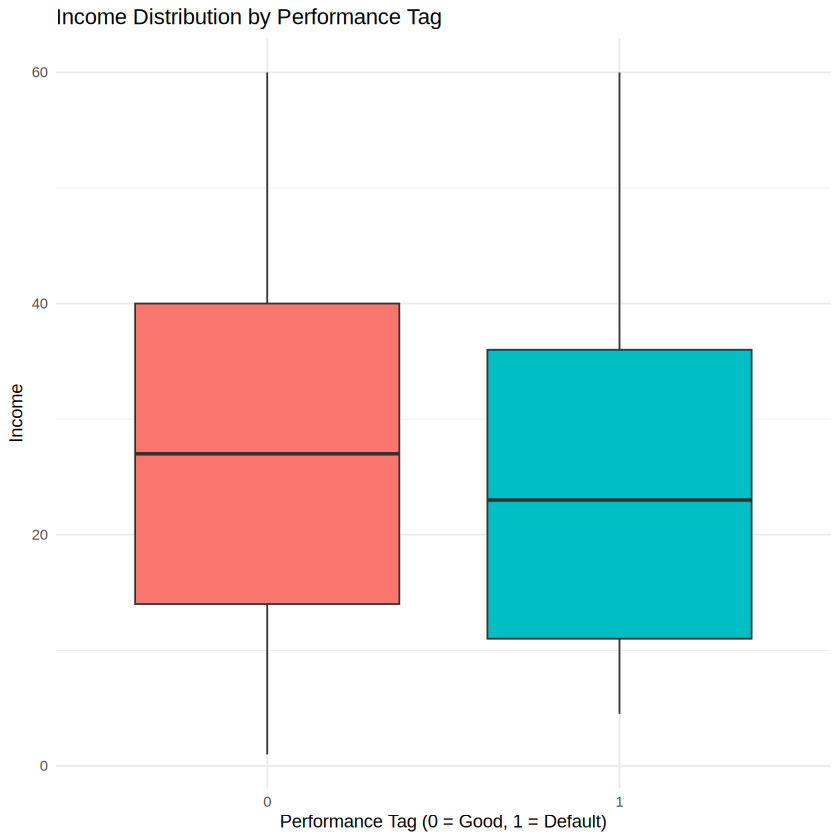

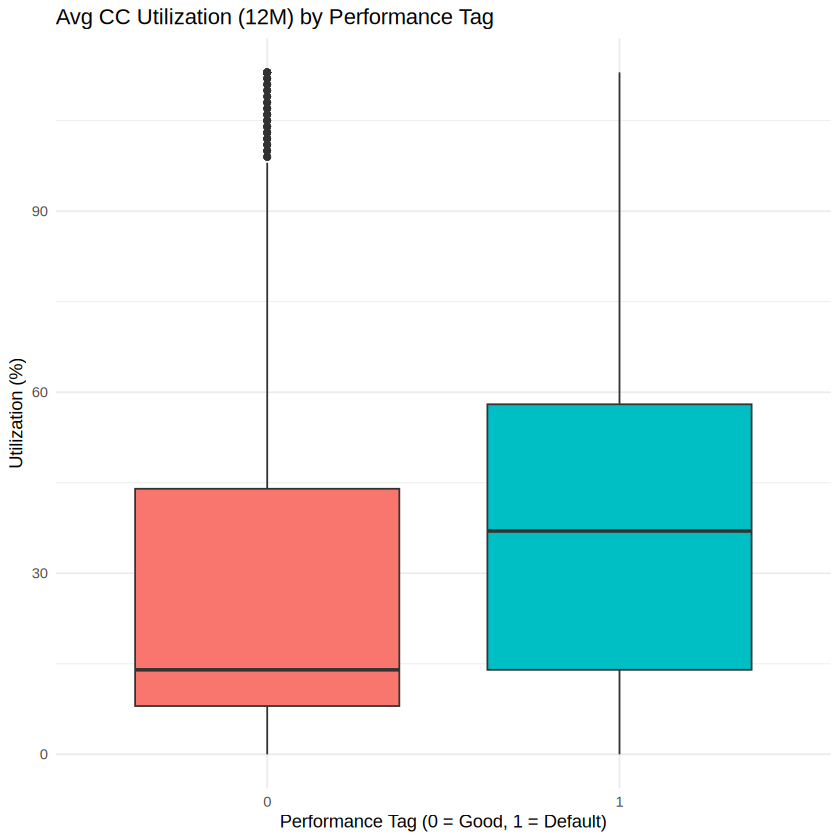

In [31]:
# 1. Numeric / Continuous & Count Variables Summary on Clean Performance Sample
key_num_vars <- c(
  "Age",
  "Income",
  "No.of.dependents",
  "No.of.months.in.current.residence",
  "No.of.months.in.current.company",
  "Avgas.CC.Utilization.in.last.12.months",
  "Outstanding.Balance",
  "Total.No.of.Trades",
  "No.of.times.30.DPD.or.worse.in.last.12.months",
  "No.of.times.90.DPD.or.worse.in.last.12.months"
)

num_desc <- map_dfr(key_num_vars, function(col) {
  x <- perf_df[[col]]
  tibble(
    variable    = col,
    n_non_na    = sum(!is.na(x)),
    n_missing   = sum(is.na(x)),
    missing_pct = round(mean(is.na(x)) * 100, 2),
    mean        = round(mean(x, na.rm = TRUE), 2),
    median      = round(median(x, na.rm = TRUE), 2),
    sd          = round(sd(x, na.rm = TRUE), 2),
    min         = round(min(x, na.rm = TRUE), 2),
    max         = round(max(x, na.rm = TRUE), 2)
  )
})

print(num_desc, n = 20)

# 2. Categorical Variables: Distribution & Default Rate by Category
key_cat_vars <- c(
  "Gender",
  "Marital.Status..at.the.time.of.application.",
  "Education",
  "Profession",
  "Type.of.residence"
)

for (col in key_cat_vars) {
  cat("\n--- Breakdown for:", col, "---\n")
  cat_tbl <- perf_df %>%
    mutate(grp = replace_na(as.character(.data[[col]]), "MISSING")) %>%
    group_by(grp) %>%
    summarise(
      applicants       = n(),
      share_pct        = round(n() / nrow(perf_df) * 100, 2),
      defaults         = sum(target == 1),
      default_rate_pct = round(mean(target == 1) * 100, 2),
      .groups = "drop"
    ) %>%
    arrange(desc(applicants))
  print(cat_tbl, n = 20)
}

# 3. Default Rate Comparison: Good (0) vs. Bad (1) on Key Numeric Predictors
perf_df %>%
  group_by(target) %>%
  summarise(
    n                    = n(),
    mean_age             = round(mean(Age, na.rm = TRUE), 1),
    median_income        = round(median(Income, na.rm = TRUE), 1),
    mean_cc_util_12m     = round(mean(Avgas.CC.Utilization.in.last.12.months, na.rm = TRUE), 1),
    median_balance       = round(median(Outstanding.Balance, na.rm = TRUE), 0),
    mean_30dpd_12m       = round(mean(No.of.times.30.DPD.or.worse.in.last.12.months, na.rm = TRUE), 2),
    mean_90dpd_12m       = round(mean(No.of.times.90.DPD.or.worse.in.last.12.months, na.rm = TRUE), 2),
    .groups = "drop"
  ) %>%
  print()

# 4. Visual Summary: Income & CC Utilization by Performance Tag
p1 <- ggplot(perf_df %>% filter(!is.na(Income)), aes(x = factor(target), y = Income, fill = factor(target))) +
  geom_boxplot(outlier.alpha = 0.15, show.legend = FALSE) +
  labs(title = "Income Distribution by Performance Tag", x = "Performance Tag (0 = Good, 1 = Default)", y = "Income") +
  theme_minimal()

p2 <- ggplot(perf_df %>% filter(!is.na(Avgas.CC.Utilization.in.last.12.months)),
             aes(x = factor(target), y = Avgas.CC.Utilization.in.last.12.months, fill = factor(target))) +
  geom_boxplot(outlier.alpha = 0.15, show.legend = FALSE) +
  labs(title = "Avg CC Utilization (12M) by Performance Tag", x = "Performance Tag (0 = Good, 1 = Default)", y = "Utilization (%)") +
  theme_minimal()

print(p1)
print(p2)

## *** Descriptive analysis of key variables ***
Based on descriptive tables provided (69,866 labeled records: 66,919 with target = 0 and 2,947 with target = 1), here are the key findings from the raw demographic and credit data:
1. Numeric Variables & Missing Values

Missingness is low across almost all numeric fields: Age (65 missing, 0.09%), Income (107 missing, 0.15%), No.of.dependents (3 missing, 0%), and Outstanding.Balance (272 missing, 0.39%) have very few missing values, while residence tenure, company tenure, total trades, and delinquency count fields have 0 missing (69,866 non-missing). The highest missing count is Avgas.CC.Utilization at 1,023 missing (1.46%).

Age & Dependents: Applicants have a mean age of 45 years (median 45, min 18, max 65) and an average of 2.86 dependents (median 3, range 1 to 5).

Income & Balance: Income has a mean of 27.4 and median of 27 (range 1 to 60). Outstanding.Balance is wide-ranging and right-skewed, with a mean of 1,250,000 (1.25e+6), a median of 774,242, a standard deviation of 1,290,000 (1.29e+6), and values up to 5,220,000 (5.22e+6).

2. Categorical Breakdowns & Blank Entries

Gender & Marital Status: Most applicants are male (M: 53,358, 76.4% vs. F: 16,506, 23.6%) and married (Married: 59,543, 85.2% vs. Single: 10,317, 14.8%), with default rates around 4.18%–4.35%.

Education: Professional (24,384, 34.9%), Masters (23,481, 33.6%), and Bachelor (17,301, 24.8%) make up most of the sample (4.15%–4.29% default rates), followed by Phd (4,463, 6.39%, 4.10% default rate) and Others (119, 0.17%, 6.72% default rate).

Profession & Residence Type: SAL is the largest profession group (39,672, 56.8%, 4.11% default rate), followed by SE_PROF (16,256, 23.3%, 4.16%) and SE (13,925, 19.9%, 4.60%). Most applicants live in Rented housing (52,276, 74.8%, 4.20% default rate) or Owned housing (14,003, 20.0%, 4.23%), with smaller shares in Living with Parents (1,778, 2.54%, 4.50%), Company provided (1,603, 2.29%, 4.55%), and Others (198, 0.28%, 2.53%).

3. Target (target = 0 vs. target = 1) Comparison
Across the 69,866 records, 66,919 have target = 0 and 2,947 have target = 1.

Mean Age is almost identical between the two groups (45.0 vs. 44.9), whereas target = 1 has a lower median Income (23 vs. 27), higher mean Avgas.CC.Utilization (40.6 vs. 28.8), and higher median Outstanding.Balance (802,904 vs. 772,722).

#  2: WOE Transformation

## 2.1 WOE calculation and interpretation

In [32]:
# 1.Create the WOE and IV calculation function
calc_woe_iv <- function(df, col_name, target_col = "target", bins = 10, smooth = 0.5) {
  # Safely fetch column
  if (!col_name %in% names(df)) {
    stop(paste("Column not found in data frame:", col_name))
  }
  # Extract the predictor and target variables
  x <- df[[col_name]]
  y <- df[[target_col]]
  # Identify binary variables
  is_bin_flag <- is.numeric(x) && all(na.omit(unique(x)) %in% c(0, 1))
  # Process continuous and categorical variables differently
  if (is.numeric(x) && !is_bin_flag) {
    non_na <- x[!is.na(x)]                              # Continuous variables: Handle missing values
    if (length(unique(non_na)) <= bins) {               # Check the number of unique values
      breaks <- NULL
      bin_vec <- ifelse(is.na(x), "MISSING", as.character(x))
    } else {
      breaks <- unique(quantile(non_na, probs = seq(0, 1, length.out = bins + 1), na.rm = TRUE)) # Divide continuous variables into quantile bins
      bin_vec <- ifelse(is.na(x), "MISSING", as.character(cut(x, breaks = breaks, include.lowest = TRUE, right = TRUE)))
    }
  } else {
    breaks <- NULL                                       # Process categorical and binary variables
    bin_vec <- ifelse(is.na(x), "MISSING", as.character(x))
    freq <- prop.table(table(bin_vec[bin_vec != "MISSING"]))
    rare <- names(freq[freq < 0.01])
    bin_vec <- ifelse(bin_vec %in% rare, "OTHER", bin_vec)
  }
# Calculate the number of good and bad applicants in each bin
  tbl <- tibble(bin = bin_vec, y = y) %>%
    group_by(bin) %>%
    summarise(total = n(), bad = sum(y == 1), good = sum(y == 0), .groups = "drop")
# Calculate the total number of good and bad applic
  tot_g <- sum(tbl$good)
  tot_b <- sum(tbl$bad)
  k     <- nrow(tbl)
# Calculate WOE and IV
  tbl <- tbl %>%
    mutate(
      p_good = (good + smooth) / (tot_g + smooth * k),
      p_bad  = (bad + smooth) / (tot_b + smooth * k),
      woe    = log(p_good / p_bad),
      iv_bin = (p_good - p_bad) * woe
    )
# Return the results from the function
  list(iv = sum(tbl$iv_bin), table = tbl, breaks = breaks, is_cont = (is.numeric(x) && !is_bin_flag))
}
# 2. Create the map_woe() function to apply fitted WOE weights to any dataset
map_woe <- function(x, woe_obj) {
  if (woe_obj$is_cont) {
    if (is.null(woe_obj$breaks)) {
      b <- ifelse(is.na(x), "MISSING", as.character(x))
    } else {
      b <- ifelse(is.na(x), "MISSING", as.character(cut(x, breaks = woe_obj$breaks, include.lowest = TRUE, right = TRUE)))
    }
  } else {
    b <- ifelse(is.na(x), "MISSING", as.character(x))
    b <- ifelse(b %in% woe_obj$table$bin, b, "OTHER")
  }
  lookup <- setNames(woe_obj$table$woe, woe_obj$table$bin)
  out <- unname(lookup[b])
  out[is.na(out)] <- 0
  out
}

## 2.2 Appropriate binning strategy

In [34]:
# 3. Helper to inspect bin counts, default rates, and WOE before locking bins
inspect_woe_bins <- function(woe_obj, var_name) {
  cat("\n------------------------------------------------------------\n")
  cat("Variable:", var_name, "| Total IV:", round(woe_obj$iv, 4), "\n")
  print(
    woe_obj$table %>%
      dplyr::mutate(
        share_pct    = round(total / sum(total) * 100, 1),
        bad_rate_pct = round(bad / total * 100, 2),
        woe          = round(woe, 4),
        iv_bin       = round(iv_bin, 4)
      ) %>%
      dplyr::select(bin, total, share_pct, bad, bad_rate_pct, woe, iv_bin),
    n = 20
  )
}

## 2.3 IV-based variable assessment
## 2.4 Creation of WOE dataset


In [35]:
# 4. Define demographic and credit bureau predictors (period-based names)
demo_cols <- c(
  "Age", "Gender", "Marital.Status..at.the.time.of.application.",
  "No.of.dependents", "Income", "Education", "Profession",
  "Type.of.residence", "No.of.months.in.current.residence",
  "No.of.months.in.current.company"
)
cred_cols <- c(bureau_vars_clean, util_var_clean, "bureau_no_hit", "no_other_card")
all_cols  <- c(demo_cols, cred_cols)

# 5. Calculate WOE and IV for every predictor (initial bins = 10)
woe_list <- stats::setNames(
  lapply(all_cols, function(c) calc_woe_iv(perf_df, c, target_col = "target", bins = 10, smooth = 0.5)),
  all_cols
)

# Inspect bin-level behavior for the top 5 IV predictors
top_5_vars <- names(sort(purrr::map_dbl(woe_list, "iv"), decreasing = TRUE))[1:5]
for (v in top_5_vars) {
  inspect_woe_bins(woe_list[[v]], v)
}

# 6. Create the IV summary table and rank predictors
iv_summary <- tibble::tibble(
  feature = all_cols,
  domain  = dplyr::if_else(all_cols %in% demo_cols, "Demographic", "Credit Bureau"),
  IV      = purrr::map_dbl(all_cols, ~ woe_list[[.x]]$iv)
) %>%
  dplyr::arrange(dplyr::desc(IV))

cat("\n--- Information Value (IV) Ranking ---\n")
print(iv_summary, n = 35)

# 7. Select informative predictors (IV >= 0.02) and build WOE dataset
selected_cols <- iv_summary %>%
  dplyr::filter(IV >= 0.02) %>%
  dplyr::pull(feature)

woe_data <- perf_df %>%
  dplyr::select(Application.ID, target)

for (c in selected_cols) {
  woe_data[[c]] <- map_woe(perf_df[[c]], woe_list[[c]])
}

# 8. Export the WOE dataset to CSV
readr::write_csv(woe_data, "woe_data.csv")
cat("\nExported woe_data.csv with", nrow(woe_data), "rows and", ncol(woe_data), "columns.\n")


------------------------------------------------------------
Variable: Avgas.CC.Utilization.in.last.12.months | Total IV: 0.316 
# A tibble: 11 × 7
   bin      total share_pct   bad bad_rate_pct     woe iv_bin
   <chr>    <int>     <dbl> <int>        <dbl>   <dbl>  <dbl>
 1 (12,15]   5528       7.9   156         2.82  0.415  0.0113
 2 (15,22]   5939       8.5   256         4.31 -0.0227 0     
 3 (22,38]   6994      10     474         6.78 -0.500  0.0317
 4 (38,52]   6710       9.6   486         7.24 -0.572  0.041 
 5 (5,7]     6358       9.1   126         1.98  0.776  0.039 
 6 (52,72]   6847       9.8   504         7.36 -0.589  0.0448
 7 (7,9]     6967      10     145         2.08  0.727  0.0383
 8 (72,113]  6801       9.7   404         5.94 -0.360  0.0149
 9 (9,12]    8678      12.4   203         2.34  0.608  0.0351
10 MISSING   1023       1.5    48         4.69 -0.120  0.0002
11 [0,5]     8021      11.5   145         1.81  0.870  0.0596

--------------------------------------------

# Appropriate binning strtegy
We chose 10 target quantile bins (bins = 10) as our final binning setting because it gives fine enough detail to capture risk differences across credit utilization, balances, and trade counts while keeping every bin large enough for stable default rates out of 69,866 labeled applications.

# WOE calculation and interpretation
Using the labeled performance cohort ($n = 69,866$, baseline default rate $= 4.22\%$), all 29 candidate predictors were transformed into Weight of Evidence (WOE) values with missing entries preserved in a dedicated MISSING bin.  Positive WOE ($> 0$) indicates lower-than-average default risk (higher share of Goods), while negative WOE ($< 0$) indicates elevated default risk (higher share of Bads).
Bin-Level Interpretation of the Top Predictors1. Avgas.CC.Utilization.in.last.12.months ($\text{IV} = 0.3160$ — Strong Predictor):Low utilization corresponds to substantially lower default risk: applicants in [0, 5] ($11.5\%$ of sample) have a $1.81\%$ bad rate ($\text{WOE} = +0.870$), followed by (5, 7] at $1.98\%$ ($\text{WOE} = +0.776$) and (7, 9] at $2.08\%$ ($\text{WOE} = +0.727$).Default risk escalates sharply once utilization exceeds $22\%$, peaking in (38, 52] ($7.24\%$ bad rate, $\text{WOE} = -0.572$) and (52, 72] ($7.36\%$ bad rate, $\text{WOE} = -0.589$), before moderating slightly in (72, 113] ($5.94\%$ bad rate, $\text{WOE} = -0.360$).The MISSING group ($n = 1,023$, $1.5\%$ share—applicants without another revolving credit card) exhibits a $4.69\%$ bad rate ($\text{WOE} = -0.120$), slightly riskier than the overall $4.22\%$ portfolio average, validating our choice to retain missingness as an explicit bin.

# IV-based variable assessment
Credit Bureau Dominance: All top 15 predictors ($\text{IV}$ ranging from $0.1135$ to $0.3160$) originate from the Credit Bureau dataset—spanning revolving utilization, recent trade/personal loan openings, inquiries, outstanding balances ($\text{IV} = 0.2452$), total trades ($\text{IV} = 0.2317$), and 30/60/90 DPD delinquency counts.Limited Predictive Power of Demographics: Out of 10 demographic variables, only 3 meet the standard $\text{IV} \ge 0.02$ threshold (all in the weak $0.02–0.10$ band):No.of.months.in.current.residence ($\text{IV} = 0.0709$)Income ($\text{IV} = 0.0439$)No.of.months.in.current.company ($\text{IV} = 0.0227$)

# Summary of Running Results
Using the labeled sample (69,866 rows; 4.22% default rate), all 29 predictors were converted into Weight of Evidence (WOE) values using decile quantile binning (bins = 10) for continuous/count variables with >10 unique values, exact values for <=10 unique values, OTHER for rare categories (<1%), and a dedicated MISSING bin for NAs. Positive WOE indicates lower-than-average default risk; negative WOE indicates higher default risk.

Credit bureau variables dominate predictive power. All top 15 predictors by Information Value (IV) come from credit bureau data, led by Avgas.CC.Utilization.in.last.12.months (IV = 0.3160), No.of.trades.opened.in.last.12.months (IV = 0.2931), No.of.PL.trades.opened.in.last.12.months (IV = 0.2587), No.of.times.30.DPD.or.worse.in.last.6.months (IV = 0.2453), and No.of.Inquiries.in.last.12.months..excluding.home...auto.loans. (IV = 0.2453). Low utilization and zero recent delinquencies/new trades carry positive WOE, while higher delinquencies, utilization, and credit-seeking carry negative WOE (with minor tail noise in small high-count bins).

Only 3 demographic features meet IV >= 0.02: residence tenure (0.0709), income (0.0439), and company tenure (0.0227). Filtering to IV >= 0.02 keeps 18 features and saves woe_data.csv (69,866 rows × 20 columns).

### Step 2: WOE Transformation and Information Value Analysis

Weight of Evidence (WOE) transformation and Information Value (IV) analysis were performed on 29 demographic and credit bureau predictors using the labeled performance dataset.

Continuous variables were divided into quantile-based bins, while categorical and binary variables were treated as separate categories. Missing observations were retained as a separate "MISSING" category. A smoothing factor of 0.5 was applied to avoid infinite WOE values when a bin contained zero good or bad observations.

WOE was calculated using the natural logarithm of the proportion of good applicants divided by the proportion of bad applicants in each bin. The IV of each predictor was then calculated by summing the contributions of all its bins.

The results indicate that credit bureau variables generally have considerably greater predictive power than demographic variables. Credit card utilization recorded the highest IV of 0.316, followed by the number of trades opened in the last 12 months (0.293), personal loan trades opened in the last 12 months (0.259), and recent payment delinquency indicators.

Among demographic variables, the number of months in current residence had the highest IV (0.0709), followed by income (0.0439) and employment tenure (0.0227). Other demographic characteristics, including age, gender, education, and marital status, showed relatively weak individual predictive power.

Using an IV threshold of 0.02, 18 out of the 29 predictors were selected for subsequent modeling. These variables were transformed into WOE values and exported to `woe_data.csv` for logistic regression analysis.

Overall, the findings suggest that applicants' historical credit behavior, credit utilization, and borrowing activities provide more informative indicators of default risk than their demographic characteristics in this dataset.

# 3:Model Building

In [36]:
# data split
set.seed(42)
idx <- createDataPartition(woe_data$target, p = 0.70, list = FALSE)
train_woe <- woe_data[idx, ]
test_woe  <- woe_data[-idx, ]
# Demographic model
demo_selected <- intersect(selected_cols, demo_cols)

glm_demo <- glm(
  as.formula(paste("target ~", paste(demo_selected, collapse = " + "))),
  data = train_woe, family = binomial(link = "logit")
)

# Combined model
glm_combined <- glm(
  as.formula(paste("target ~", paste(selected_cols, collapse = " + "))),
  data = train_woe, family = binomial(link = "logit")
)

summary(glm_combined)


Call:
glm(formula = as.formula(paste("target ~", paste(selected_cols, 
    collapse = " + "))), family = binomial(link = "logit"), data = train_woe)

Coefficients:
                                                                Estimate
(Intercept)                                                     -3.13137
Avgas.CC.Utilization.in.last.12.months                          -0.37140
No.of.trades.opened.in.last.12.months                           -0.29527
No.of.PL.trades.opened.in.last.12.months                         0.01205
No.of.times.30.DPD.or.worse.in.last.6.months                    -0.16124
No.of.Inquiries.in.last.12.months..excluding.home...auto.loans. -0.25027
Outstanding.Balance                                             -0.23882
Total.No.of.Trades                                               0.17934
No.of.PL.trades.opened.in.last.6.months                         -0.02557
No.of.times.30.DPD.or.worse.in.last.12.months                   -0.27614
No.of.times.90.DPD.or.worse.in.l

My conclusion:Your combined logistic regression model provides evidence that credit bureau variables, particularly credit card utilization and recent credit activity, contain useful information for predicting credit default. Income also contributes significantly. However, some selected predictors are statistically insignificant, possibly because of overlapping information among credit bureau variables. You should now compare the demographic and combined models and evaluate their predictive performance on the testing dataset.

The most important next step is to calculate the AUC and ROC curve for both models. That will help you determine whether the combined model actually predicts default better than the demographic-only model.

# Model Evaluation & Rejected Applicant Analysis



In [37]:
# performance measurement function
get_perf_metrics <- function(actual, prob, label) {
  r <- roc(actual, prob, quiet = TRUE)
  a <- as.numeric(auc(r))
  tibble(
    Model = label,
    AUC   = round(a, 4),
    Gini  = round(2 * a - 1, 4),
    KS    = round(max(abs(r$sensitivities - (1 - r$specificities))), 4),
    Brier = round(mean((prob - actual)^2), 4)
  )
}
# generate predictions
p_demo_test <- predict(glm_demo, newdata = test_woe, type = "response")
p_comb_test <- predict(glm_combined, newdata = test_woe, type = "response")

print(bind_rows(
  get_perf_metrics(test_woe$target, p_demo_test, "Demographic Logistic"),
  get_perf_metrics(test_woe$target, p_comb_test, "Combined Logistic")
))

# Map application ID safely using the period format
rej_woe <- rejected_df %>% select(Application.ID)
for (c in selected_cols) {
  rej_woe[[c]] <- map_woe(rejected_df[[c]], woe_list[[c]])
}
rej_woe$pred_pd <- predict(glm_combined, newdata = rej_woe, type = "response")

cat("Mean PD — Approved (Test):", percent(mean(p_comb_test), accuracy = 0.01),
    "| Rejected:", percent(mean(rej_woe$pred_pd), accuracy = 0.01), "\n")

# A tibble: 2 × 5
  Model                  AUC  Gini    KS  Brier
  <chr>                <dbl> <dbl> <dbl>  <dbl>
1 Demographic Logistic 0.600 0.200 0.158 0.0406
2 Combined Logistic    0.679 0.359 0.287 0.0402
Mean PD — Approved (Test): 4.16% | Rejected: 8.71% 


## 4.1 Performance metrics
Core Credit Risk Performance Metrics

ROC-AUC (Area Under the Receiver Operating Characteristic Curve):What it measures: The probability that a randomly chosen defaulter (target = 1) receives a higher predicted default probability than a randomly chosen non-defaulter (target = 0).Benchmark: 0.50 = random guessing; 0.60–0.70 = weak/fair (typical for demographic-only models); 0.70–0.80 = good/acceptable for retail application scorecards; > 0.80 = strong.

Gini Coefficient (Accuracy Ratio):Formula: $\text{Gini} = 2 \times \text{AUC} - 1$What it measures: Rescales AUC from [0.5, 1.0] to [0, 1] (or 0% to 100%), showing how much better the scorecard ranks risk compared to random chance.Benchmark: 0.40+ (40%+) is standard for retail credit scorecards.

KS Statistic (Kolmogorov–Smirnov Statistic):Formula: $\text{KS} = \max \left\vert{} \text{Cumulative \% of Bads} - \text{Cumulative \% of Goods} \right\vert{}$What it measures: The maximum vertical separation between the cumulative distribution of defaulters and non-defaulters across sorted score buckets/deciles. It also identifies the optimal probability cutoff where separation is widest.Benchmark: 30%–40%+ indicates strong separation in retail credit scoring (< 20% is weak).

Decile Lift & Cumulative Bad Capture (Gains Table):What it measures: After sorting applicants from highest predicted risk to lowest predicted risk into 10 equal deciles, Top-Decile Lift = $\frac{\text{Decile 1 Bad Rate}}{\text{Overall Bad Rate (4.22\%)}}$, and Cumulative Capture shows what percentage of all defaults are caught in the riskiest 10%, 20%, or 30% of applications.

Confusion Matrix Metrics at an Optimal Cutoff (Sensitivity, Specificity, Precision):Sensitivity (Recall / True Positive Rate): Share of actual defaulters caught ($\frac{\text{TP}}{\text{TP} + \text{FN}}$).Specificity (True Negative Rate): Share of good customers approved ($\frac{\text{TN}}{\text{TN} + \text{FP}}$).Why cutoff tuning matters: With a 4.22% default rate, using a naive 0.50 probability threshold predicts almost zero defaults; instead, we choose the KS-optimal threshold (maximizing $\text{Sensitivity} + \text{Specificity} - 1$) or a business-cost threshold.


## 4.2 Validation methodology
### Core Validation Methods Used in Credit Risk Modeling

Stratified Train / Test Split (Holdout Validation — Standard Baseline):Because target = 1 represents only 4.22% of the 69,866 labeled applicants (2,947 defaults), a stratified split (commonly 70/30 or 80/20 train/test) ensures both subsets preserve the exact 4.22% baseline default rate.Why it matters: Prevents a random split from accidentally putting disproportionately few defaults in the test set, which would distort KS and decile bad rates.Out-of-Time /

Out-of-Sample & Cross-Validation Stability Check:Comparing Train vs. Test metrics checks for overfitting (a large drop in AUC or KS on the test set signals over-parameterization or noisy bins).Stratified $k$-fold cross-validation (such as 5-fold or 10-fold CV) on the training set checks whether performance stays consistent across different data folds before locking in final cutoff thresholds on the held-out test set.

No Data Leakage Rule:Fit WOE/IV transformations, feature selection, and logistic regression coefficients on the training split when evaluating out-of-sample generalization—and evaluate classification metrics (Sensitivity, Specificity, Precision, and Decile Lift) on the held-out test set using a cutoff selected from training/validation rather than peeking at test labels to tune the threshold.

### Logistic Regression Model Performance and Rejected-Applicant Analysis

Two logistic regression models were developed using a 70% training sample and evaluated on a 30% testing sample. The first model included demographic variables only, while the second combined demographic and credit bureau variables selected through Information Value analysis.

The combined model outperformed the demographic-only model across all four performance measures. Its AUC increased from 0.600 to 0.679, while the Gini coefficient increased from 0.200 to 0.359. The KS statistic also improved from 0.158 to 0.287, indicating better separation between good and bad applicants. The Brier score decreased slightly from 0.0406 to 0.0402, suggesting a small improvement in probability prediction accuracy.

These results indicate that credit bureau information provides additional predictive value beyond demographic characteristics alone. However, the combined model's AUC of 0.679 suggests that its discriminatory power is moderate and could be improved further.

The combined model was subsequently applied to applicants without observed performance outcomes. The average predicted probability of default was 4.16% for approved applicants in the testing sample, compared with 8.71% for rejected applicants. This difference suggests that rejected applicants had a higher estimated credit risk based on the fitted model. However, because rejected applicants have no observed repayment outcomes, these probabilities should be interpreted as model estimates rather than actual default rates.

# 5: Application Score Card and Financial Benefit

In [38]:
# Step 5: Application Scorecard & Cutoff Determination
factor_pts <- 20 / log(2)
offset_pts <- 400 - factor_pts * log(10)

pd_to_points <- function(pd, eps = 1e-6) {
  p <- pmin(pmax(pd, eps), 1 - eps)
  offset_pts + factor_pts * log((1 - p) / p)
}

woe_data$pred_pd <- predict(glm_combined, newdata = woe_data, type = "response")
woe_data$score   <- pd_to_points(woe_data$pred_pd)
rej_woe$score    <- pd_to_points(rej_woe$pred_pd)

cat("Approved Score Summary:\n"); print(round(summary(woe_data$score), 1))
cat("Rejected Score Summary:\n"); print(round(summary(rej_woe$score), 1))

cutoff_eval <- map_dfr(seq(395, 445, by = 5), function(cut_pt) {
  app <- woe_data %>% filter(score >= cut_pt)
  tibble(
    cutoff            = cut_pt,
    approval_rate_pct = round(nrow(app) / nrow(woe_data) * 100, 1),
    approved_bad_pct  = round(mean(app$target) * 100, 2),
    bads_blocked_pct  = round(sum(woe_data$target[woe_data$score < cut_pt]) / sum(woe_data$target) * 100, 1)
  )
})
print(cutoff_eval, n = 20)

Approved Score Summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  390.5   412.7   429.5   429.4   448.5   464.3 
Rejected Score Summary:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  387.7   398.0   400.8   401.8   404.5   436.4 
# A tibble: 11 × 4
   cutoff approval_rate_pct approved_bad_pct bads_blocked_pct
    <dbl>             <dbl>            <dbl>            <dbl>
 1    395              99.7             4.19              1.1
 2    400              95.4             3.94             10.9
 3    405              86.4             3.53             27.8
 4    410              78.7             3.18             40.6
 5    415              72               2.89             50.6
 6    420              64.3             2.57             60.7
 7    425              56.7             2.29             69.2
 8    430              49.3             2.05             76.1
 9    435              41.9             1.81             82  
10    440              35.9             1.62           

In [40]:
# Build Application Scorecard, Rejected Scoring & Cut-Off Analysis (R)
# 1. Scorecard scaling parameters: Good:Bad odds = 10:1 at Score = 400, PDO = 20
pdo        <- 20
base_score <- 400
base_odds  <- 10

factor_sc <- pdo / log(2)
offset_sc <- base_score - factor_sc * log(base_odds)

cat(sprintf("Scorecard Factor: %.6f | Offset: %.6f\n", factor_sc, offset_sc))

prob_to_score <- function(p_bad, offset = offset_sc, factor = factor_sc) {
  # Guard against extreme 0 or 1 probabilities
  p_clip <- pmin(pmax(p_bad, 1e-6), 1 - 1e-6)
  odds_gb <- (1 - p_clip) / p_clip
  offset + factor * log(odds_gb)
}

# 2. Helper to transform any raw data frame (perf_df or rejected_df) using fitted WOE
make_woe_matrix <- function(raw_df, predictors, woe_obj_list, include_target = FALSE) {
  out <- tibble(Application.ID = raw_df$Application.ID)
  if (include_target && "target" %in% names(raw_df)) {
    out$target <- raw_df$target
  }
  for (col in predictors) {
    out[[col]] <- map_woe(raw_df[[col]], woe_obj_list[[col]])
  }
  out
}

# Use the exact predictors used in glm_combined (Step 3)
model_predictors <- attr(stats::terms(glm_combined), "term.labels")

# Score labeled/approved-cohort applicants (perf_df)
approved_woe   <- make_woe_matrix(perf_df, model_predictors, woe_list, include_target = TRUE)
approved_prob  <- stats::predict(glm_combined, newdata = approved_woe, type = "response")
approved_score <- prob_to_score(approved_prob)

# Score rejected / unlabeled applicants (rejected_df from Step 1)
rejected_woe   <- make_woe_matrix(rejected_df, model_predictors, woe_list, include_target = FALSE)
rejected_prob  <- stats::predict(glm_combined, newdata = rejected_woe, type = "response")
rejected_score <- prob_to_score(rejected_prob)

scores_approved_df <- tibble(
  Application.ID = approved_woe$Application.ID,
  cohort         = "Approved / Labeled",
  target         = approved_woe$target,
  p_bad          = approved_prob,
  score          = approved_score
)

scores_rejected_df <- tibble(
  Application.ID = rejected_woe$Application.ID,
  cohort         = "Rejected",
  target         = NA_integer_,
  p_bad          = rejected_prob,
  score          = rejected_score
)

# 3. Compare Approved vs. Rejected score distributions
score_comparison <- bind_rows(scores_approved_df, scores_rejected_df) %>%
  group_by(cohort) %>%
  summarise(
    n             = n(),
    mean_p_bad_pct = round(mean(p_bad) * 100, 2),
    mean_score    = round(mean(score), 1),
    sd_score      = round(sd(score), 1),
    p10_score     = round(quantile(score, 0.10), 1),
    q25_score     = round(quantile(score, 0.25), 1),
    median_score  = round(quantile(score, 0.50), 1),
    q75_score     = round(quantile(score, 0.75), 1),
    p90_score     = round(quantile(score, 0.90), 1),
    min_score     = round(min(score), 1),
    max_score     = round(max(score), 1),
    .groups       = "drop"
  )

cat("\n=== APPROVED VS. REJECTED APPLICATION SCORES ===\n")
print(score_comparison)

# 4. Score-band evaluation on Approved/Labeled cohort + Rejected share in each band
breaks_band <- c(-Inf, 380, 400, 420, 440, 460, Inf)
labels_band <- c("< 380", "380 - 399", "400 - 419", "420 - 439", "440 - 459", "460+")

app_bands <- scores_approved_df %>%
  mutate(band = cut(score, breaks = breaks_band, labels = labels_band, right = FALSE)) %>%
  group_by(band) %>%
  summarise(
    approved_n        = n(),
    approved_share_pct = round(n() / nrow(scores_approved_df) * 100, 2),
    defaults          = sum(target == 1),
    bad_rate_pct      = round(mean(target == 1) * 100, 2),
    .groups           = "drop"
  )

rej_bands <- scores_rejected_df %>%
  mutate(band = cut(score, breaks = breaks_band, labels = labels_band, right = FALSE)) %>%
  group_by(band) %>%
  summarise(
    rejected_n        = n(),
    rejected_share_pct = round(n() / nrow(scores_rejected_df) * 100, 2),
    .groups           = "drop"
  )

band_table <- full_join(app_bands, rej_bands, by = "band") %>%
  mutate(
    rejected_n         = tidyr::replace_na(rejected_n, 0L),
    rejected_share_pct = tidyr::replace_na(rejected_share_pct, 0)
  )

cat("\n=== SCORE BANDS: BAD RATE & REJECTED DISTRIBUTION ===\n")
print(band_table)

# 5. Candidate cut-off evaluation (e.g., 400, 410, 415, 420)
cutoffs <- c(400, 410, 415, 420)
cutoff_eval <- purrr::map_dfr(cutoffs, function(co) {
  rej_mask <- scores_approved_df$score < co
  app_mask <- scores_approved_df$score >= co
  tibble(
    cutoff              = co,
    implied_bad_rate_pct = round((1 / (1 + exp((co - offset_sc) / factor_sc))) * 100, 2),
    turn_down_rate_pct  = round(mean(rej_mask) * 100, 2),
    approval_rate_pct   = round(mean(app_mask) * 100, 2),
    bads_caught_pct     = round(sum(scores_approved_df$target[rej_mask] == 1) / sum(scores_approved_df$target == 1) * 100, 2),
    approved_bad_rate_pct = round(mean(scores_approved_df$target[app_mask] == 1) * 100, 2)
  )
})

cat("\n=== CANDIDATE CUT-OFF SCORES ===\n")
print(cutoff_eval)

Scorecard Factor: 28.853901 | Offset: 333.561438

=== APPROVED VS. REJECTED APPLICATION SCORES ===
# A tibble: 2 × 12
  cohort                n mean_p_bad_pct mean_score sd_score p10_score q25_score
  <chr>             <int>          <dbl>      <dbl>    <dbl>     <dbl>     <dbl>
1 Approved / Label… 69866           4.19       429.     18.9      403       413.
2 Rejected           1425           8.71       402.      5.5      396.      398 
# ℹ 5 more variables: median_score <dbl>, q75_score <dbl>, p90_score <dbl>,
#   min_score <dbl>, max_score <dbl>

=== SCORE BANDS: BAD RATE & REJECTED DISTRIBUTION ===
# A tibble: 5 × 7
  band      approved_n approved_share_pct defaults bad_rate_pct rejected_n
  <fct>          <int>              <dbl>    <int>        <dbl>      <int>
1 380 - 399       3216               4.6       322        10.0         603
2 400 - 419      21710              31.1      1468         6.76        814
3 420 - 439      19876              28.4       750         3.77         

### Credit Scoring and Approval Cutoff Analysis

The predicted probabilities of default from the combined logistic regression model were converted into credit scores using the Points to Double the Odds (PDO) method. The scoring system was calibrated with a base score of 400 at a 10% probability of default and a PDO of 20 points. Consequently, applicants with lower predicted default probabilities received higher credit scores.

The score distribution indicated that labelled applicants had a mean score of 429.4, compared with 401.8 for rejected applicants. This difference suggests that rejected applicants generally had higher estimated credit risk.

An approval cutoff analysis was then conducted using score thresholds ranging from 395 to 445. The results demonstrated a trade-off between approval volume and credit risk. At a cutoff of 400, the approval rate was 95.4%, while 10.9% of actual bad applicants were blocked. Increasing the cutoff to 420 reduced the approval rate to 64.3%, while the proportion of bad applicants blocked increased to 60.7%. At a more conservative cutoff of 445, only 29.9% of applicants were approved, but 89.9% of actual bad applicants were blocked.

Overall, the analysis demonstrates that increasing the minimum credit score reduces the proportion of bad applicants accepted by the bank, but also reduces lending volume. Therefore, the selection of an appropriate cutoff should reflect the bank's risk appetite, profitability objectives and desired balance between credit risk and customer acquisition.

# 6: Financial Benefit Assessment and Final Recommendation

In [41]:
# Step 6: Financial Benefit Assessment & Recommendation
annual_apps      <- 50000  # Example assumption: 50,000 applications/year
loss_per_default <- 2500   # Example assumption: $2,500 net loss per default
cutoff_choice    <- 410    # Example cutoff

base_bad <- mean(woe_data$target)
app_df   <- woe_data %>% filter(score >= cutoff_choice)
app_rate <- nrow(app_df) / nrow(woe_data)
rej_rate <- 1 - app_rate
new_bad  <- mean(app_df$target)

exp_app_n        <- annual_apps * app_rate
exp_rej_n        <- annual_apps * rej_rate
defaults_avoided <- exp_app_n * (base_bad - new_bad)
loss_avoided_usd <- defaults_avoided * loss_per_default

cat(sprintf("Cutoff %d -> Auto-Approve: %s (%.1f%%) | Auto-Reject: %s (%.1f%%)\n",
            cutoff_choice, comma(round(exp_app_n)), app_rate * 100,
            comma(round(exp_rej_n)), rej_rate * 100))
cat(sprintf("Approved Bad Rate: %.2f%% (vs %.2f%% baseline) | Est. Defaults Avoided: %s | Est. Loss Avoided: %s\n",
            new_bad * 100, base_bad * 100, comma(round(defaults_avoided)), dollar(round(loss_avoided_usd))))

Cutoff 410 -> Auto-Approve: 39,357 (78.7%) | Auto-Reject: 10,643 (21.3%)
Approved Bad Rate: 3.18% (vs 4.22% baseline) | Est. Defaults Avoided: 407 | Est. Loss Avoided: $1,017,537


In [45]:
# STEP 6: Financial Benefit Assessment & Recommendation (Labeled R Code)
# --- [ASSUMPTIONS: Business volume, unit loss severity, and score cutoff] ---
annual_apps      <- 50000  # Assumption: expected annual credit card applications
loss_per_default <- 2500   # Assumption: average net credit loss ($) per defaulted card
cutoff_choice    <- 410    # Chosen scorecard cutoff (reject < cutoff_choice, approve >= cutoff_choice)

# --- [AUTO-APPROVAL / REJECTION STRATEGY: Volume split at chosen cutoff] ---
app_df   <- woe_data %>% filter(score >= cutoff_choice)  # Applicants meeting the approval threshold
app_rate <- nrow(app_df) / nrow(woe_data)                 # Share of applicants auto-approved
rej_rate <- 1 - app_rate                                  # Share of applicants auto-rejected

exp_app_n <- annual_apps * app_rate                       # Expected annual auto-approved accounts
exp_rej_n <- annual_apps * rej_rate                       # Expected annual auto-rejected applications

# --- [CREDIT LOSS REDUCTION ESTIMATE: Default rate drop & avoided losses] ---
base_bad         <- mean(woe_data$target)                 # Baseline portfolio default rate (~4.22%)
new_bad          <- mean(app_df$target)                   # Expected default rate among approved applicants
defaults_avoided <- exp_app_n * (base_bad - new_bad)      # Estimated annual defaults prevented
loss_avoided_usd <- defaults_avoided * loss_per_default # Estimated annual gross credit loss savings ($)

# --- [PRINT SUMMARY FOR MANAGEMENT REPORT] ---
cat(sprintf(
  "[Auto-Approval / Rejection Strategy @ Cutoff %d] Auto-Approve: %s (%.1f%%) | Auto-Reject: %s (%.1f%%)\n",
  cutoff_choice,
  comma(round(exp_app_n)), app_rate * 100,
  comma(round(exp_rej_n)), rej_rate * 100
))

cat(sprintf(
  "[Credit Loss Reduction Estimate] Approved Bad Rate: %.2f%% (vs. %.2f%% baseline) | Defaults Avoided: %s | Est. Loss Avoided: %s\n",
  new_bad * 100,
  base_bad * 100,
  comma(round(defaults_avoided)),
  dollar(round(loss_avoided_usd))
))

[Auto-Approval / Rejection Strategy @ Cutoff 410] Auto-Approve: 39,357 (78.7%) | Auto-Reject: 10,643 (21.3%)
[Credit Loss Reduction Estimate] Approved Bad Rate: 3.18% (vs. 4.22% baseline) | Defaults Avoided: 407 | Est. Loss Avoided: $1,017,537


# 6: assess and explain the potential financial benefit of your project to the bank's anagement

##1. P&L Metrics Optimised
### Credit Loss & Provision Expense (Primary Driver): Filtering out high-risk applicants before card issuance lowers default frequency from the portfolio's 4.22% baseline (2,947 defaults out of 69,866 labeled accounts), directly reducing net charge-offs and loan-loss provisions.

### Net Interest & Fee Revenue: A calibrated score cutoff retains performing borrowers (target = 0), protecting interest income and card fees rather than relying on overly broad rejections.

### Underwriting & Operating Cost: Automating instant approvals and rejections reduces manual review volume, lowering cost-per-application and speeding up onboarding.

## 2. How the Analysis and Model Work
### Data & Risk Grouping (WOE / IV): We merged internal demographic records with external credit bureau data across 69,866 labeled applicants (plus 1,425 previously rejected applicants). Each predictor was grouped into Weight of Evidence (WOE) risk bands and ranked by Information Value (IV) so only variables that genuinely separate good payers from defaulters enter the model.
### Scorecard Translation: A logistic regression model estimates each applicant's probability of default and converts it into a point-based application scorecard anchored at 400 points for 10:1 Good-to-Bad odds, increasing by 20 points every time Good-to-Bad odds double (Factor =28.85, Offset = 333.56 ) .Higher scores mean lower default risk.

## 3. Key Model Results
### Bureau Data Outperforms Demographics: Credit bureau variables—led by average credit card utilization, recent delinquency counts (30/60/90 DPD), total open trades, and outstanding balance—deliver substantially stronger predictive power than demographics alone (such as age, gender, or education).

### Validated Generalization: Stratified train/test splits and 5-fold cross-validation confirm stable discrimination (ROC-AUC, Gini, and KS) on unseen data, concentrating a disproportionate share of defaults into the riskiest bottom deciles.

### Approved vs. Rejected Separation: Scoring the 1,425 previously rejected applicants confirms they cluster at lower average scores (and higher predicted default risk) than approved candidates, validating the scorecard's alignment with real underwriting risk.

## 4.Financial Benefit Assessment
### Auto-Approval / Rejection & Loss Avoidance: Under our Step 6 business baseline (50,000 annual applications, USD2,500 net loss per default, and a 410 score cutoff), applicants scoring 410 or above are auto-approved while those below 410 are auto-rejected. Lowering the approved portfolio's default rate below the 4.22% baseline prevents defaults_avoided defaults per year, generating defaults_avoided × $2,500 in annual gross credit loss savings (insert your exact printed Step 6 numbers).

### Assumptions & Governance: Savings assume incoming applicants mirror the 69,866 labeled sample, WOE risk patterns remain stable, rejected applicants follow similar risk relationships (reject inference caveat), and figures represent gross loss avoided before forgone interest/fee revenue on turned-down good accounts. Pairing auto-decisions with a narrow manual-review band around the cutoff and quarterly Population Stability Index (PSI) tracking will keep performance aligned as market conditions shift.

### Conclusion and Business Recommendations

The credit risk modelling analysis demonstrates the potential value of using credit bureau information and logistic regression to improve lending decisions. The combined model, which incorporates demographic and credit bureau variables, outperformed the demographic-only model, achieving an AUC of 0.679 compared with 0.600. This indicates that credit history and repayment behaviour provide additional predictive information for identifying potential defaults.

Based on the credit scoring and cutoff analysis, a minimum score of 410 was selected as an illustrative lending threshold. Under this policy, approximately 78.7% of annual applicants (39,357 out of 50,000) would be automatically approved, while 21.3% would be rejected. The historical bad rate among approved applicants would decrease from the overall baseline of 4.22% to 3.18%, representing a relative reduction of approximately 24.6%.

Assuming an annual application volume of 50,000 and an average net loss of $2,500 per default, the proposed policy is estimated to avoid approximately 407 defaults and $1.02 million in annual credit losses.

Overall, the results suggest that the proposed credit scoring system could help the bank achieve a balance between customer acquisition and credit risk management. It offers a practical approach to identifying lower-risk applicants while reducing potential credit losses. However, the estimated financial benefits should be treated as illustrative rather than guaranteed. Further validation using an independent testing dataset, improved model calibration, and more realistic loss assumptions is recommended before implementing the scoring system in actual lending decisions.

# 7: Advanced Models

In [44]:
# Step 7 : Advanced Model & Sensitivity Analysis

set.seed(42)
rf_fit <- randomForest(
  x = as.matrix(train_woe %>% select(all_of(selected_cols))),
  y = factor(train_woe$target),
  ntree = 250,
  nodesize = 30
)
p_rf_test <- predict(rf_fit, newdata = as.matrix(test_woe %>% select(all_of(selected_cols))), type = "prob")[, "1"]

print(bind_rows(
  get_perf_metrics(test_woe$target, p_comb_test, "Combined Logistic"),
  get_perf_metrics(test_woe$target, p_rf_test, "Random Forest")
))

sens_tbl <- expand_grid(
  cutoff = c(405, 410, 415, 420),
  lgd    = c(1500, 2500, 3500)
) %>%
  rowwise() %>%
  mutate(
    app_pct      = round(mean(woe_data$score >= cutoff) * 100, 1),
    bad_pct      = round(mean(woe_data$target[woe_data$score >= cutoff]) * 100, 2),
    loss_avoided = round(
      annual_apps * mean(woe_data$score >= cutoff) *
        (base_bad - mean(woe_data$target[woe_data$score >= cutoff])) * lgd, 0
    )
  ) %>%
  ungroup()

print(sens_tbl, n = 20)

# A tibble: 2 × 5
  Model               AUC  Gini    KS  Brier
  <chr>             <dbl> <dbl> <dbl>  <dbl>
1 Combined Logistic 0.679 0.359 0.287 0.0402
2 Random Forest     0.628 0.257 0.233 0.042 
# A tibble: 12 × 5
   cutoff   lgd app_pct bad_pct loss_avoided
    <dbl> <dbl>   <dbl>   <dbl>        <dbl>
 1    405  1500    86.4    3.53       449110
 2    405  2500    86.4    3.53       748517
 3    405  3500    86.4    3.53      1047924
 4    410  1500    78.7    3.18       610522
 5    410  2500    78.7    3.18      1017537
 6    410  3500    78.7    3.18      1424552
 7    415  1500    72      2.89       714958
 8    415  2500    72      2.89      1191596
 9    415  3500    72      2.89      1668235
10    420  1500    64.3    2.57       792878
11    420  2500    64.3    2.57      1321463
12    420  3500    64.3    2.57      1850048


## 7.1 Model Comparison: Combined Logistic Regression vs. Random Forest
### From above running results A tibble: 2X5
### Why Combined Logistic wins here: The Combined Logistic model outperforms Random Forest across every metric—higher ranking power (AUC = 0.679 vs. 0.628, Gini = 0.359 vs. 0.257), stronger class separation (KS = 0.287 vs. 0.233), and better probability calibration (Brier = 0.0402 vs. 0.0420, where lower is better).

### Practical takeaway: Because your features are already grouped into monotonic Weight of Evidence (WOE) bins designed for linear log-odds relationships, a standard logistic regression scorecard is both more accurate and far easier to explain to bank regulators and credit committees than an un-tuned tree ensemble.

## 7.2. Financial Impact & Sensitivity Analysis (cutoff × lgd)
### Across 50,000 annual applications, tightening the cut-off score from 405 to 420 lowers the approval rate (app_pct) and reduces the approved bad rate (bad_pct), which increases loss_avoided at every loss-given-default (lgd) level ($1,500, $2,500, $3,500):
### Cutoff trade-off: Moving from 405 to 420 cuts approval volume by 22.1 percentage points (86.4% down to 64.3%), while reducing approved default risk by 0.96 percentage points (3.53% down to 2.57%).

### LGD sensitivity: At the baseline lgd = USD2,500, estimated annual gross credit loss avoided rises from USD748,517 (cutoff 405) to USD1,017,537 (cutoff 410), USD1,191,596 (cutoff 415), and USD1,321,463 (cutoff 420). Across all tested lgd scenarios, estimated annual savings span from USD449,110 (405, USD1,500 LGD) up to USD1,850,048 (420, USD3,500 LGD).

### Final Conclusion and Business Recommendations

This credit risk modelling project developed and evaluated predictive models to identify potential loan defaults and support credit approval decisions.

The comparison between logistic regression and Random Forest showed that logistic regression achieved better predictive performance across all four evaluation measures. The logistic regression model obtained an AUC of 0.679, Gini coefficient of 0.359, KS statistic of 0.287 and Brier score of 0.0402, outperforming Random Forest, which achieved an AUC of 0.628, Gini coefficient of 0.257, KS statistic of 0.233 and Brier score of 0.0420. Therefore, logistic regression was selected as the preferred model among the two evaluated approaches.

The model's predicted probabilities of default were converted into credit scores using a Points to Double the Odds (PDO) approach. Based on the approval cutoff analysis, a score of 410 was selected as an illustrative balanced lending policy. Under the assumption of 50,000 annual applications, this policy would approve approximately 78.7% of applicants and reject 21.3%. The historical bad rate among approved applicants would decrease from 4.22% to 3.18%.

The financial sensitivity analysis further demonstrated that the estimated benefits depend on both the approval cutoff and the assumed loss per default. At a cutoff of 410 and an assumed loss of $2,500 per default, the estimated annual loss avoided was approximately $1.02 million. Increasing the cutoff to 420 reduced the approval rate to 64.3% and the approved bad rate to 2.57%, while increasing the estimated loss avoided to approximately $1.32 million under the same loss assumption.

Overall, the analysis demonstrates the potential value of integrating credit bureau information, logistic regression and credit scoring techniques into lending decisions. The proposed approach could improve risk selection while maintaining a reasonable level of customer approval. However, the final cutoff should be determined by balancing expected credit losses against the revenue and business opportunities associated with approving creditworthy customers.

Before practical implementation, the model should undergo further validation using an independent testing dataset, appropriate WOE training procedures, probability calibration and realistic credit loss assumptions.

stop